# Building a model together: P4HE, Nov 19, 2026

**Everything here runs on synthetic data: fake people, not real youth.** The results show how the method behaves. They aren't findings about Native American youth.

Today the room chose which factors the computer gets to look at. The computer then looks for patterns in a simulated survey, using the same kind of model as the Indigenous Wholistic Factors Project (IWFP; Sierra 2026, [PMC12424082](https://pmc.ncbi.nlm.nih.gov/articles/PMC12424082/)).

Three rules for reading what follows:
1. **These are fake people.**
2. **"Goes with" isn't "causes."**
3. **Kept isn't the same as important.** The model keeps what predicts best, not what matters most for prevention.

## Setup

In [15]:
%matplotlib inline
%config InlineBackend.figure_format = "retina"

import json
import os

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

import figures as fig
import load_votes as lv
import pipeline as pl
import synthetic_data as sd

BOARD_ID = os.environ.get("P4HE_DEMO_BOARD", "p4he-nov19")
TOP_N = 0            # 0 = every item with at least one vote (the board has 25)

# Leave as None for live votes. Set to a file to use it instead:
#   "p4he_rehearsal_votes.csv"   rehearsal votes (tell the room these aren't theirs)
RESULTS_CSV = None

# Plain-language labels from the P4HE board
P4HE_ITEMS = json.load(open("p4he_items.json"))
lv.LABELS.update({i["id"]: i["label"] for i in P4HE_ITEMS})
labels = lv.LABELS

plt.rcParams.update({"font.size": 15, "axes.titlesize": 18})   # readable on Zoom

## 1. What the room chose

Longer bars mean more dots. This shows what *we* valued. It doesn't yet say anything about what predicts.

**Live votes from board 'p4he-nov19'. Saved to results/.**  
207 dots on 25 of 25 factors.

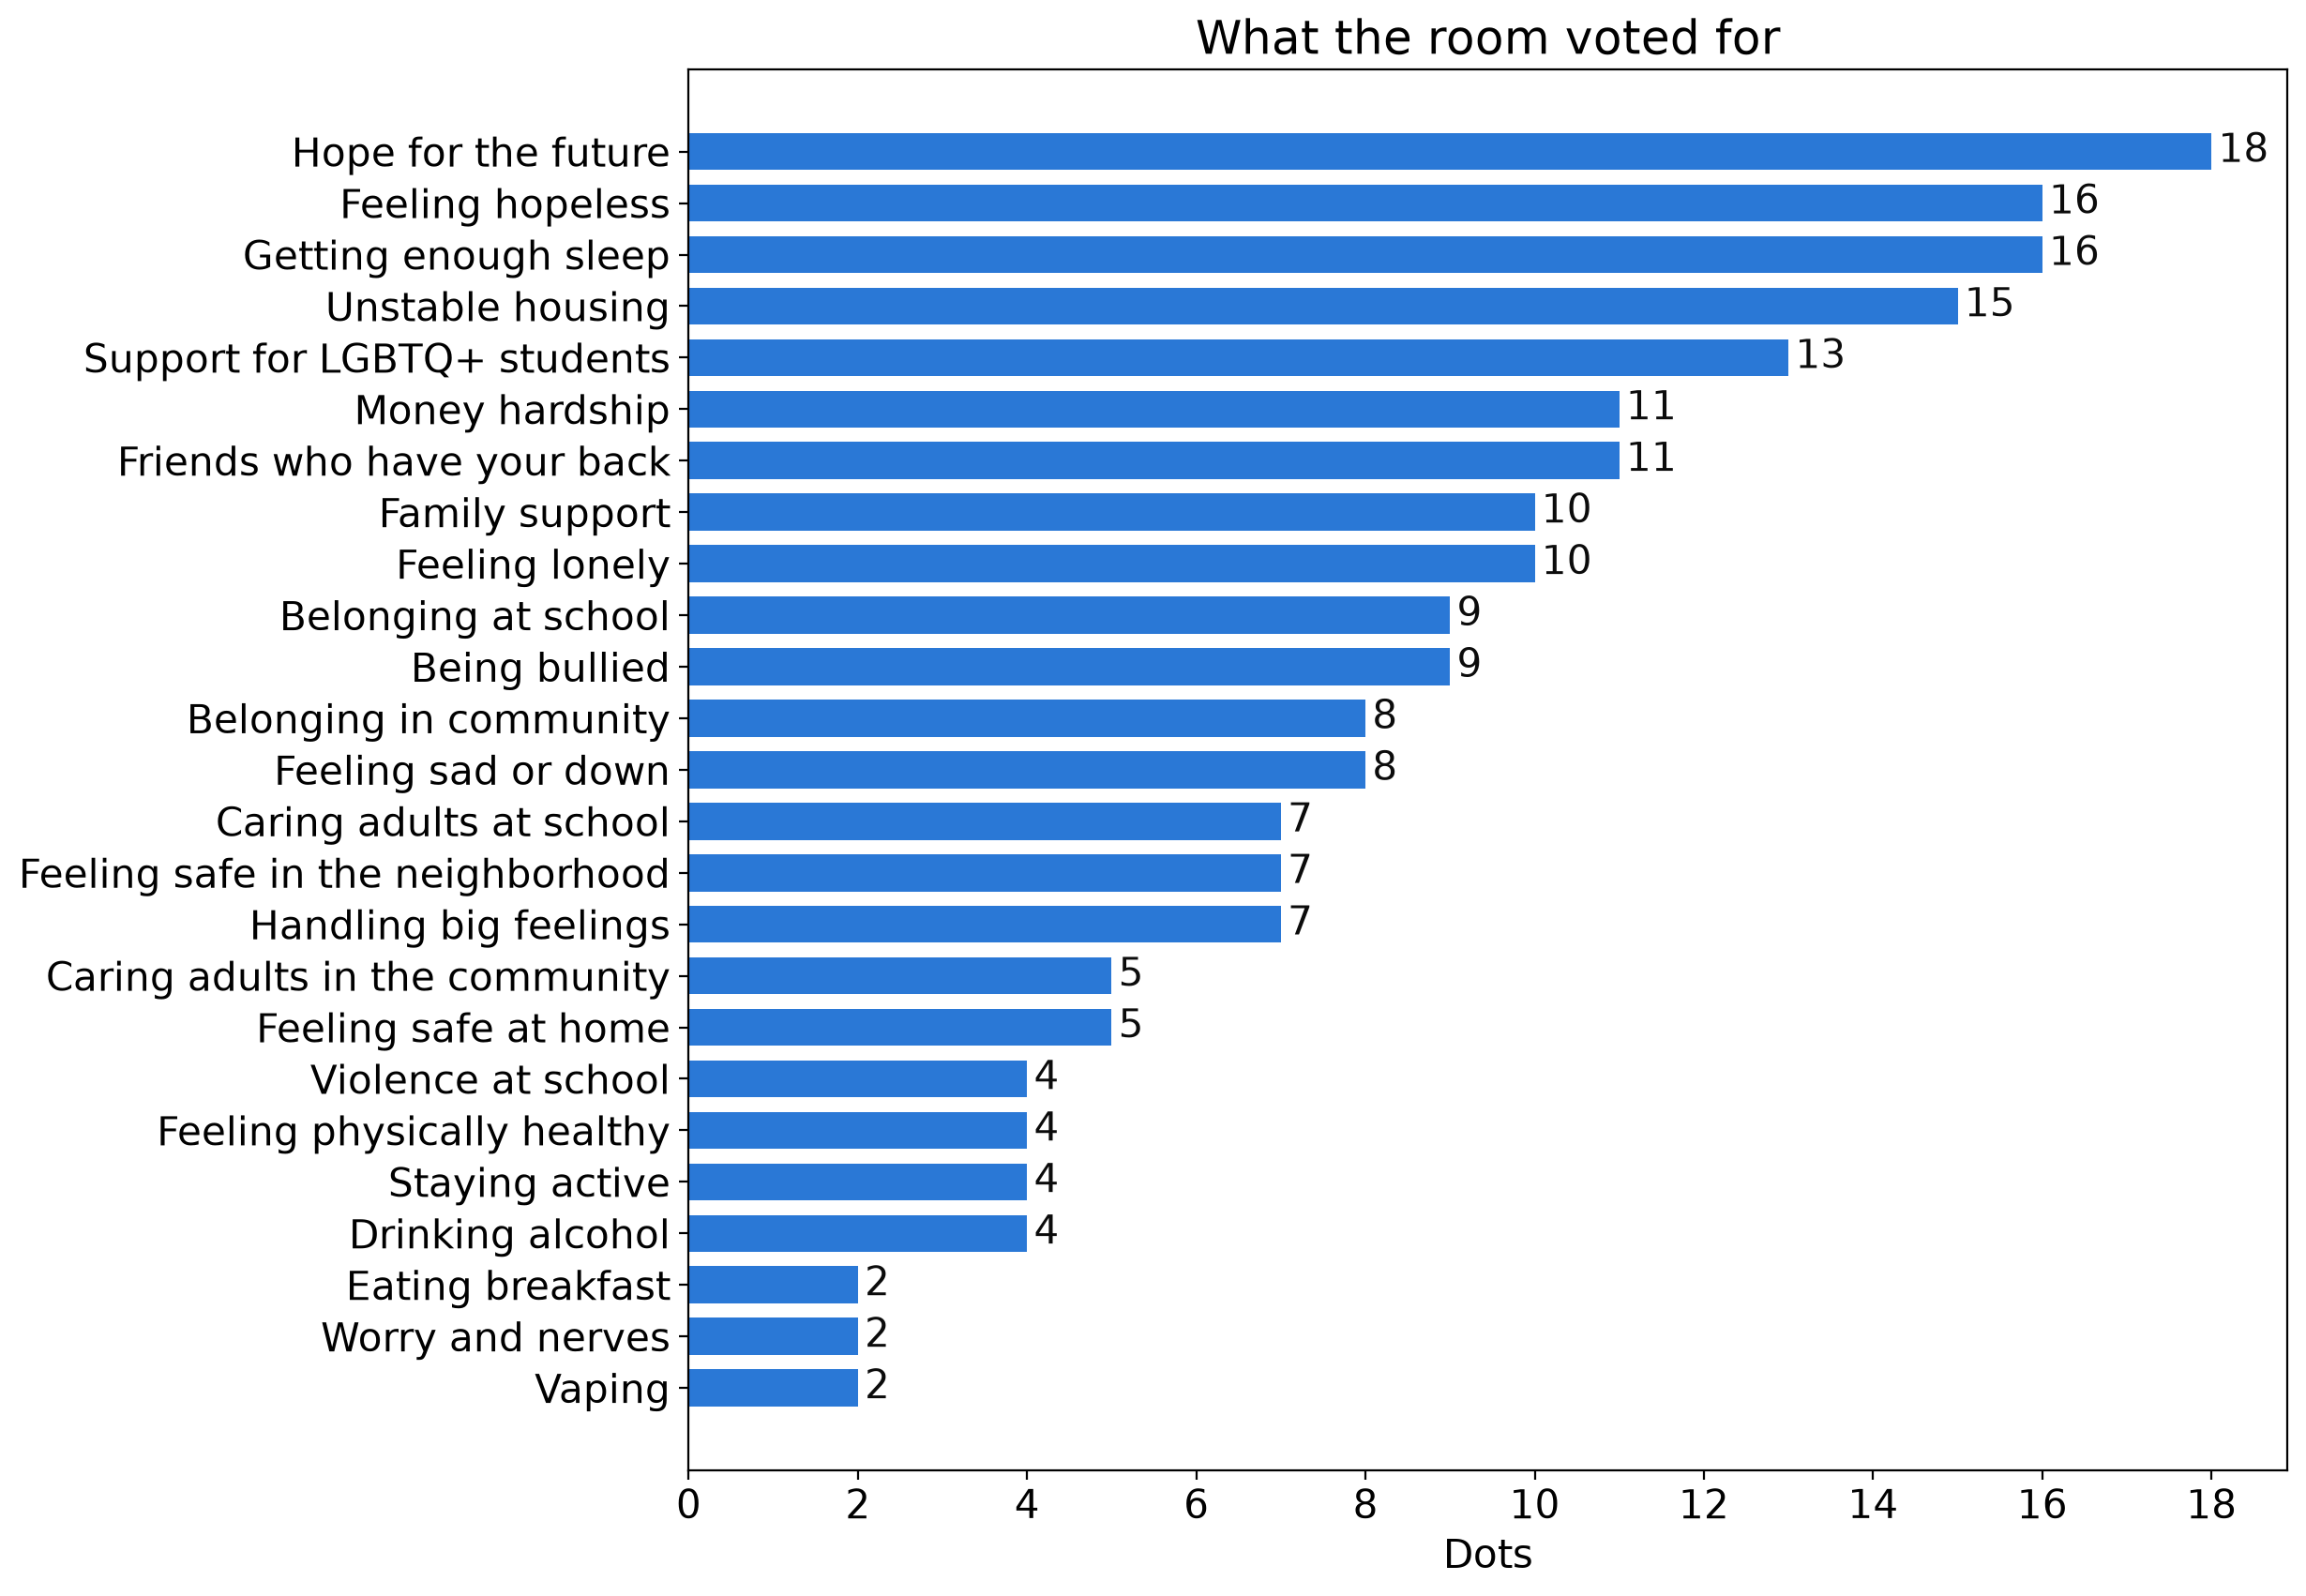

In [16]:
votes, source = lv.load_votes(BOARD_ID, RESULTS_CSV)
votes = votes[votes["item_id"].isin([i["id"] for i in P4HE_ITEMS])]
ranked, _ = lv.top_voted(votes, TOP_N)
ranked["label"] = ranked["item_id"].map(labels)
candidates = ranked["item_id"].tolist()

display(Markdown(f"**{source}**  \n{votes['vote_count'].sum()} dots on {len(candidates)} of {len(votes)} factors."))
fig.votes_chart(ranked, title="What the room voted for");

## 2. Fake people, real shape

The real survey data are private and protected, so we built 2,609 fake students whose answers look like the real survey's overall patterns. About 17% report thinking about suicide in the past year, the same as the real study.

In [17]:
df = sd.generate()
print(f"{len(df):,} synthetic students. {df['si'].mean():.0%} report suicidal thoughts (simulated).")
df[candidates[:6] + ["si"]].rename(columns=labels | {"si": "Suicidal thoughts (outcome)"}).head()

2,609 synthetic students. 17% report suicidal thoughts (simulated).


,Hope for the future,Feeling hopeless,Getting enough sleep,Unstable housing,Support for LGBTQ+ students,Money hardship,Suicidal thoughts (outcome)
0,2,1,0,0,2,1,0
1,1,3,2,0,1,1,0
2,1,1,2,0,1,1,0
3,3,0,2,0,1,0,0
4,2,1,1,0,2,1,0


## 3. Let the computer look for patterns

This one line is the model. LASSO tries every factor the room picked, and it shrinks the ones that don't help predict to zero, so only the strongest patterns stay. We also re-run it 100 times on reshuffled data and count only factors that keep showing up.

In [18]:
result = pl.run_lasso(df, candidates)
print(f"The model kept {len(result['selected_features'])} of the room's {len(candidates)} factors.")

The model kept 14 of the room's 25 factors.


## 4. What the room valued and what the model kept

Each bar is the room's dots. The color shows what the model did with that factor.

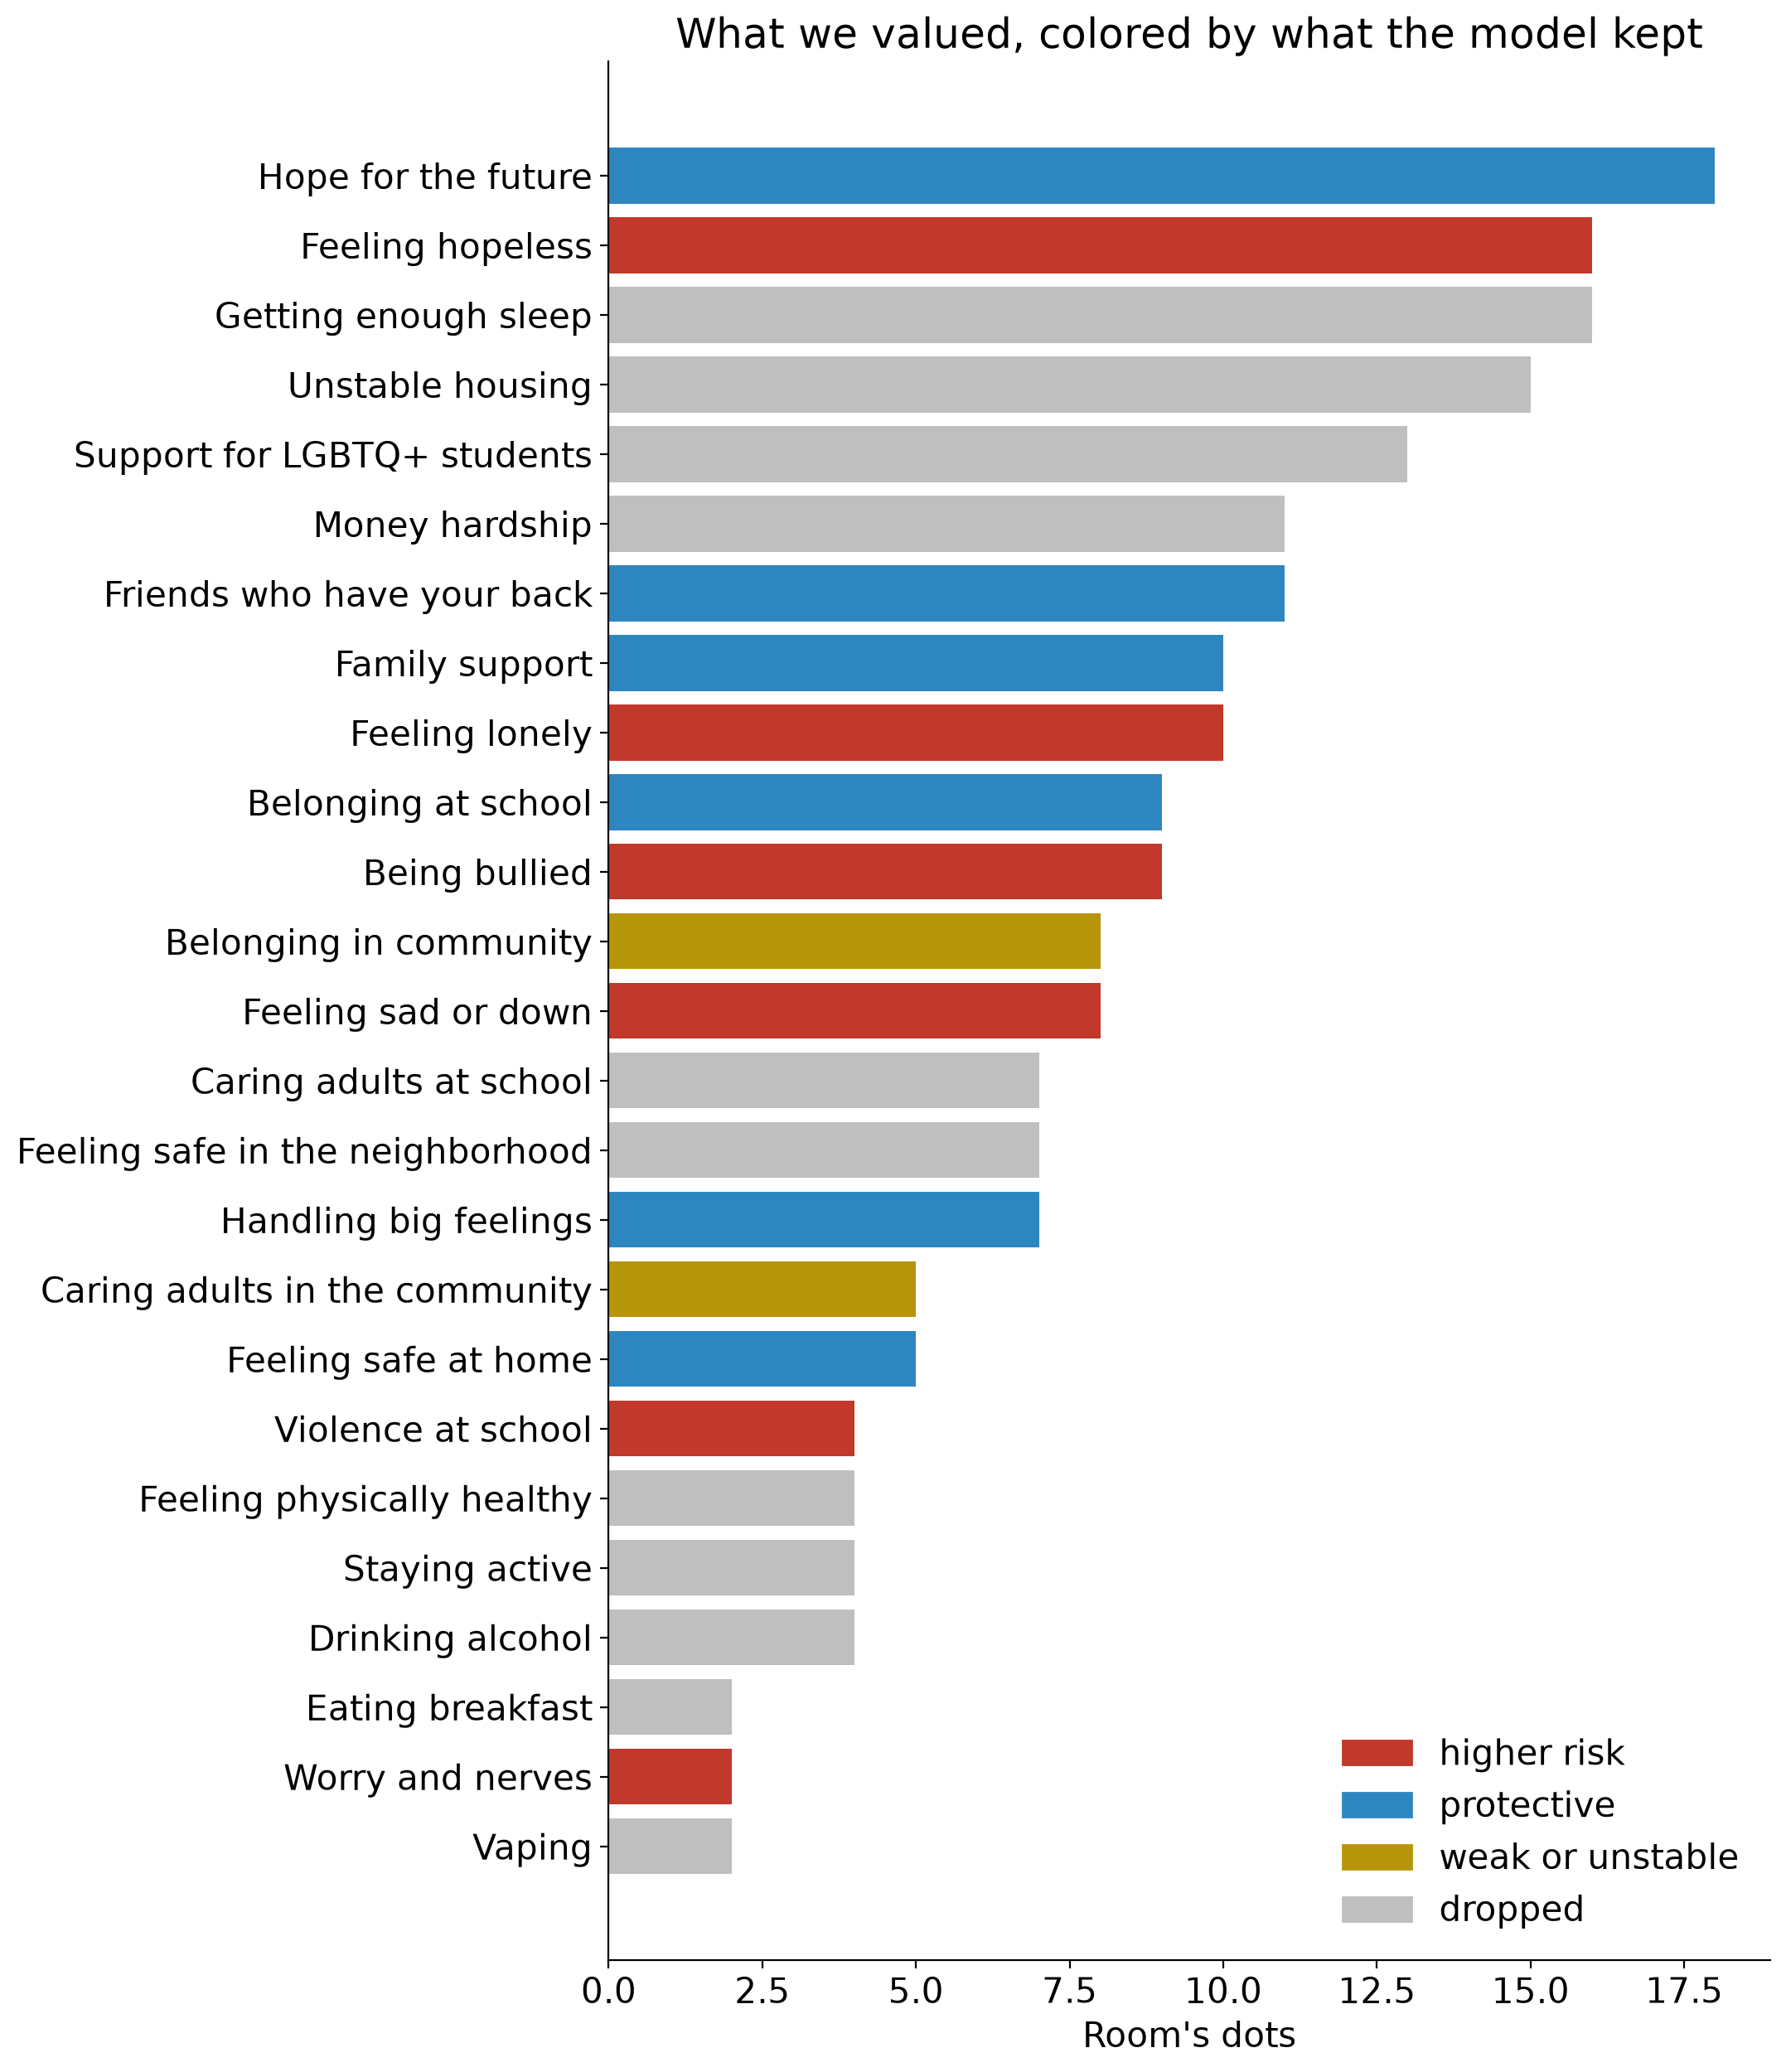

In [19]:
COLORS = {"higher risk": "#c0392b", "protective": "#2e86c1", "weak or unstable": "#b7950b", "dropped": "#bfbfbf"}
summary = ranked.assign(result=[pl.classify(result, f) for f in candidates]).iloc[::-1]

fig_, ax = plt.subplots(figsize=(11, 0.45 * len(summary) + 1.5))
ax.barh(summary["label"], summary["vote_count"], color=summary["result"].map(COLORS))
ax.set_xlabel("Room's dots")
ax.set_title("What we valued, colored by what the model kept")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=k) for k, c in COLORS.items()], loc="lower right", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

In [20]:
y = df["si"].to_numpy()
perf = pl.performance(y, pl.out_of_fold_risk(df, candidates))
print(f"Cross-validated AUC {perf['auc']:.2f} ({perf['auc_low']:.2f} to {perf['auc_high']:.2f}). "
      "0.5 is a coin flip, 1 is perfect. The published IWFP model on real data: 0.87.")

Cross-validated AUC 0.89 (0.87 to 0.91). 0.5 is a coin flip, 1 is perfect. The published IWFP model on real data: 0.87.


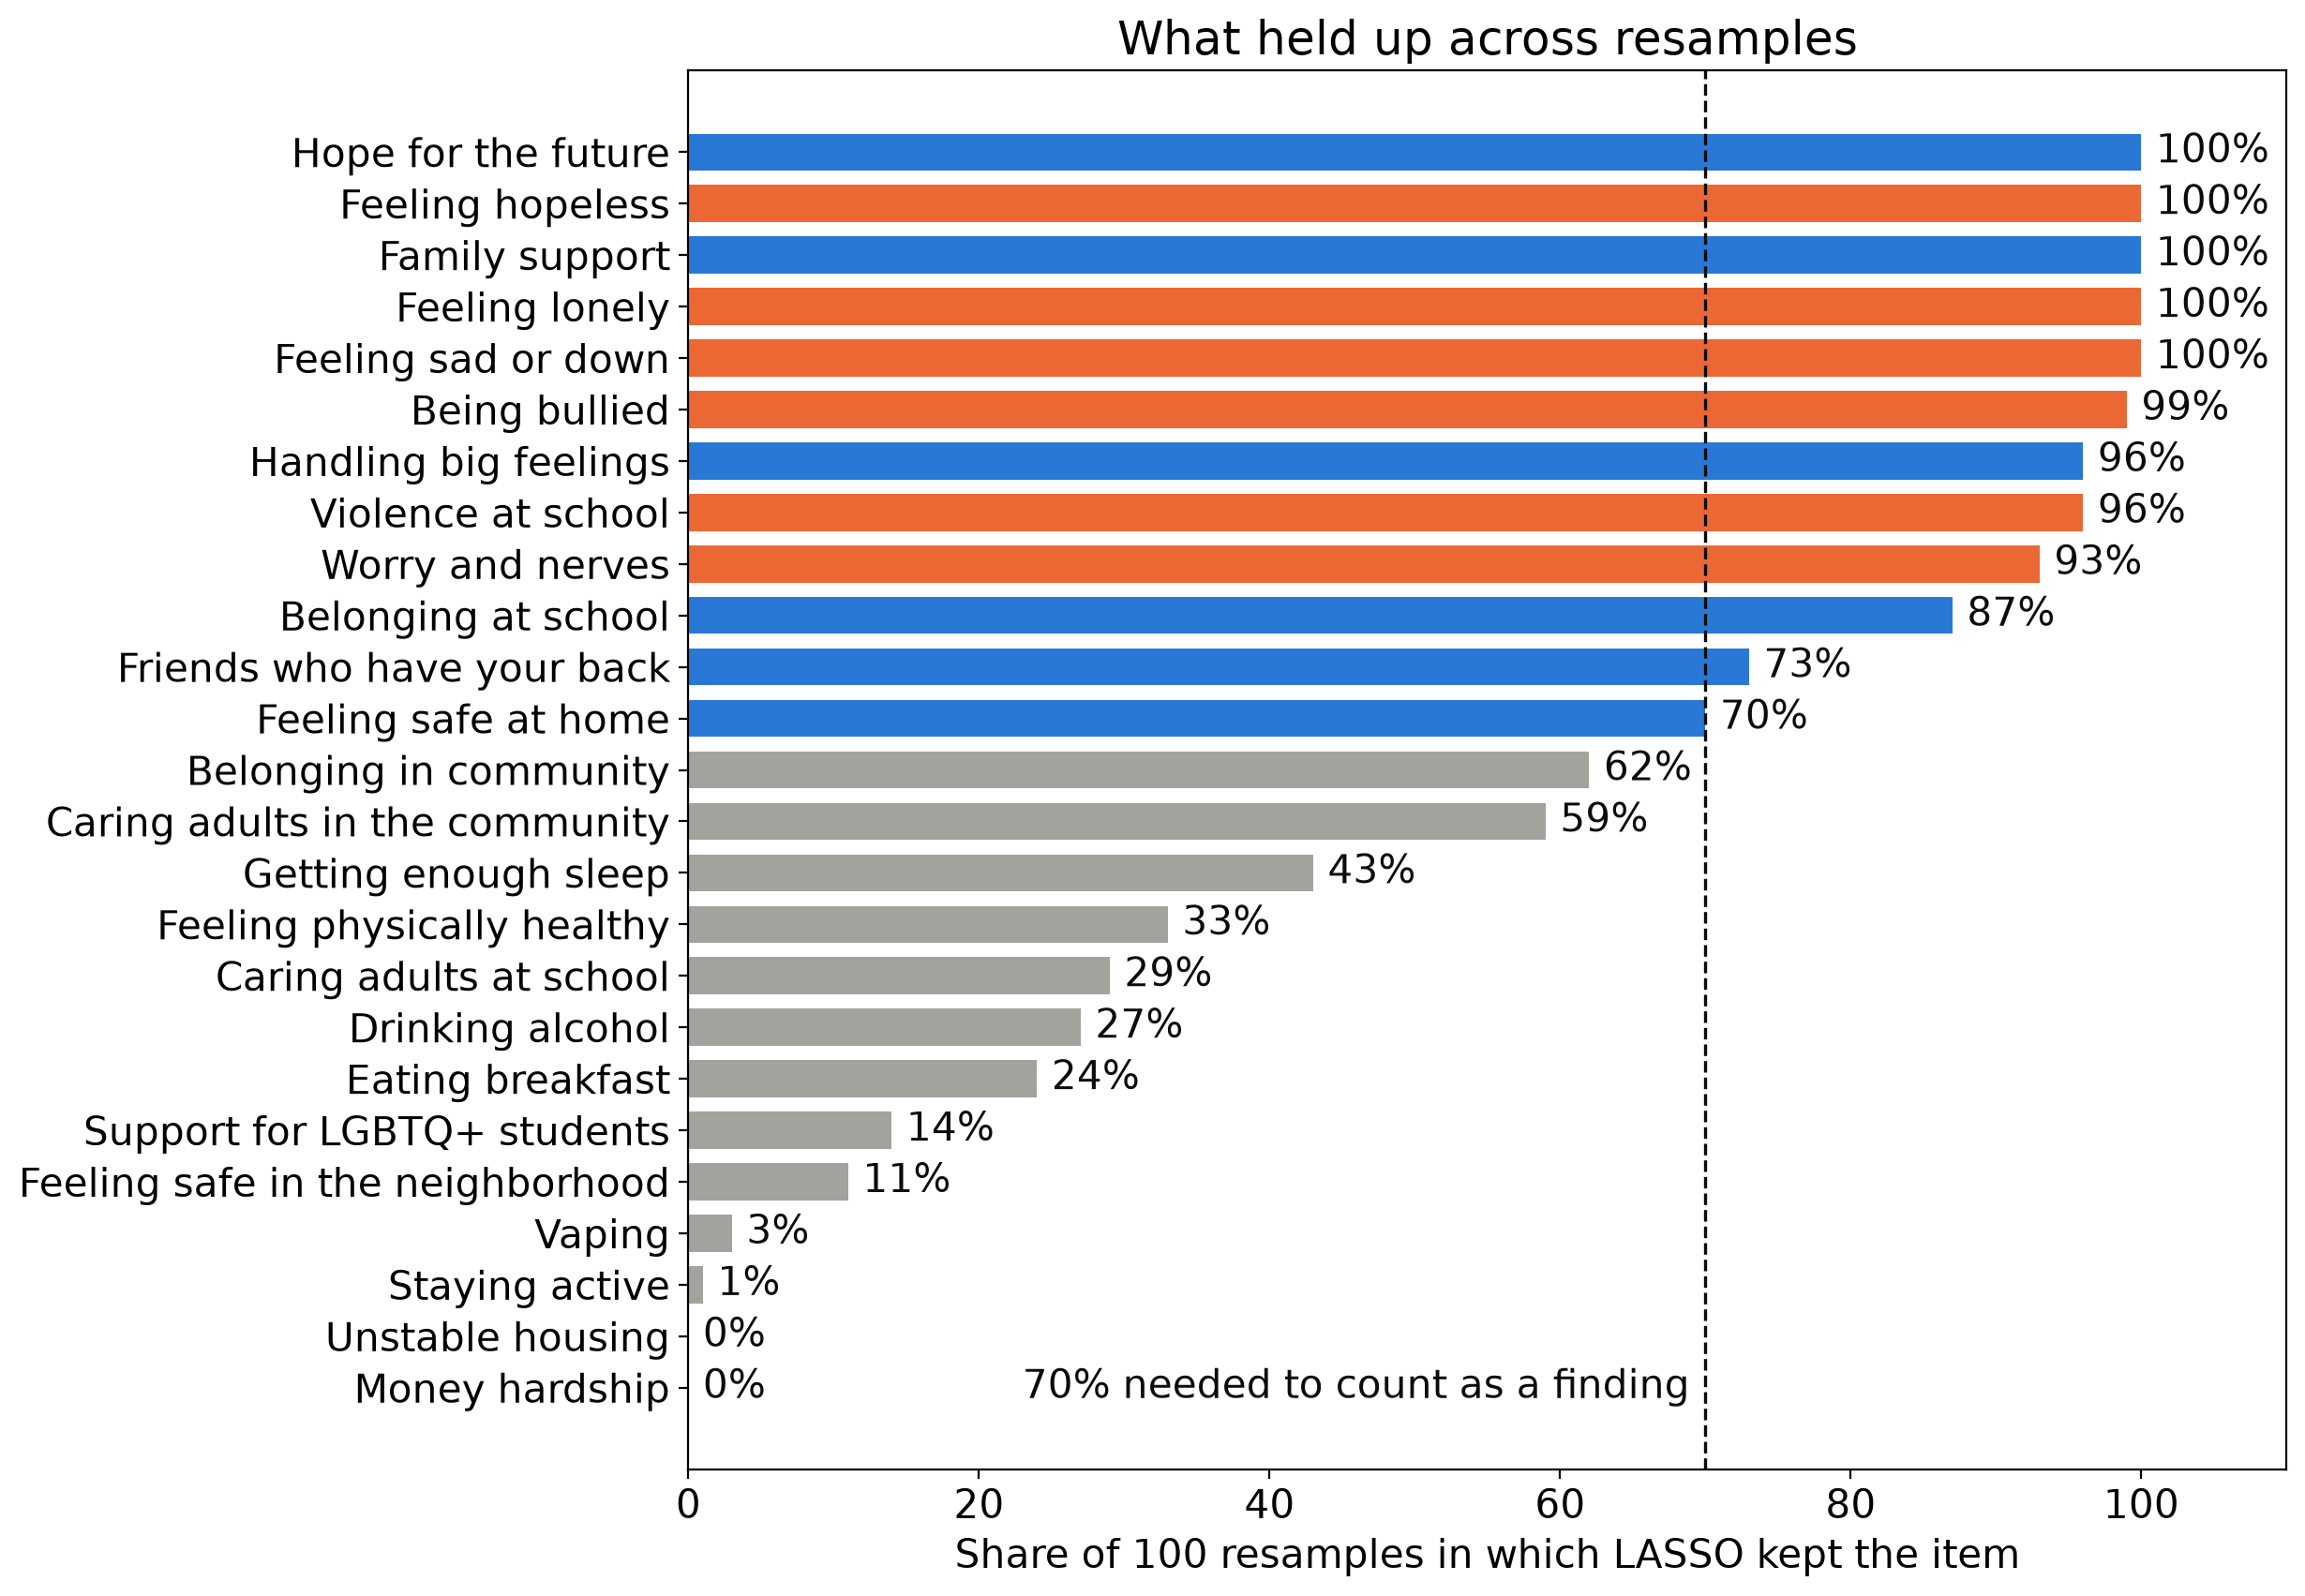

In [21]:
fig.stability_chart(result, labels, pl.classify);

## 5. In plain words

In [22]:
WORDS = {"higher risk": "goes with MORE risk", "protective": "goes with LESS risk (protective)",
         "weak or unstable": "not clear, a weak or unstable pattern", "dropped": "dropped, another factor carried its signal or it added little"}
for result_type in WORDS:
    names = [labels[f] for f in candidates if pl.classify(result, f) == result_type]
    if names:
        display(Markdown(f"**{WORDS[result_type][0].upper() + WORDS[result_type][1:]}:** " + ", ".join(names)))

**Goes with MORE risk:** Feeling hopeless, Feeling lonely, Being bullied, Feeling sad or down, Violence at school, Worry and nerves

**Goes with LESS risk (protective):** Hope for the future, Friends who have your back, Family support, Belonging at school, Handling big feelings, Feeling safe at home

**Not clear, a weak or unstable pattern:** Belonging in community, Caring adults in the community

**Dropped, another factor carried its signal or it added little:** Getting enough sleep, Unstable housing, Support for LGBTQ+ students, Money hardship, Caring adults at school, Feeling safe in the neighborhood, Feeling physically healthy, Staying active, Drinking alcohol, Eating breakfast, Vaping

## Let's talk

- **What surprised you?**
- **What did the model drop that you'd still act on?** Dropped doesn't mean unimportant. Similar factors compete, so one can carry another's signal.
- **What's missing from the board?** Culture, ceremony, language and land weren't asked in the survey, so no model can find them.
- **Who chooses the factors in your own work, and how could communities choose them?**

---
# Appendix

In [23]:
from datetime import datetime

table = summary.iloc[::-1][["label", "vote_count", "result"]].assign(
    odds_ratio_per_sd=[result["odds_ratios"].get(f) for f in candidates],
    kept_in_resamples=[round(result["stability"][f], 2) for f in candidates])
os.makedirs("results", exist_ok=True)
run_name = os.path.splitext(os.path.basename(RESULTS_CSV))[0] if RESULTS_CSV else BOARD_ID
path = f"results/{datetime.now():%Y-%m-%d_%H%M%S}_{run_name}_model_results.csv"
table.to_csv(path, index=False)
print(f"Saved {path}")

Saved results/2026-11-19_130754_p4he-nov19_model_results.csv
